# Praca domowa - regresja (housing.csv)

Import bibliotek

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib as mp
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
import sklearn

print('Python:       ' + sys.version.split()[0])
print('NumPy:        ' + np.__version__)
print('pandas:       ' + pd.__version__)
print('Matplotlib:   ' + mp.__version__)
print('Seaborn:      ' + sns.__version__)
print('Scikit-learn: ' + sklearn.__version__)

Python:       3.14.0
NumPy:        2.2.6
pandas:       2.3.3
Matplotlib:   3.11.2
Seaborn:      0.13.2
Scikit-learn: 1.7.2


# Zadanie 1: Wczytanie i wstepne przygotowanie danych

a) wczytanie danych

In [2]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


b) informacje o zbiorze i statystyki

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


c) unikalne wartosci ocean_proximity

In [5]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

# Zadanie 2: Wizualizacja danych

a) wykres slupkowy ocean_proximity

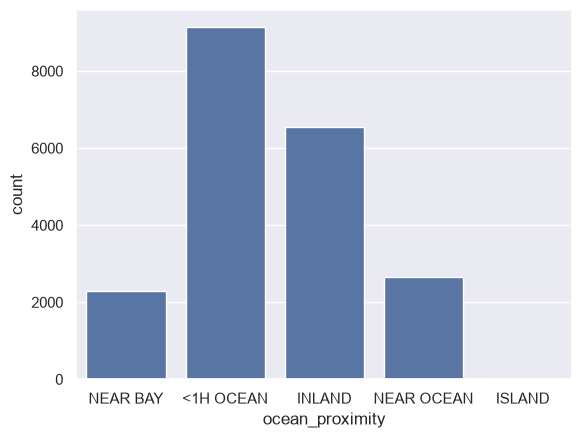

In [6]:
sns.countplot(df, x='ocean_proximity')
plt.show()

b) relacje par zmiennych (bez dlugosci i szerokosci geograficznej)

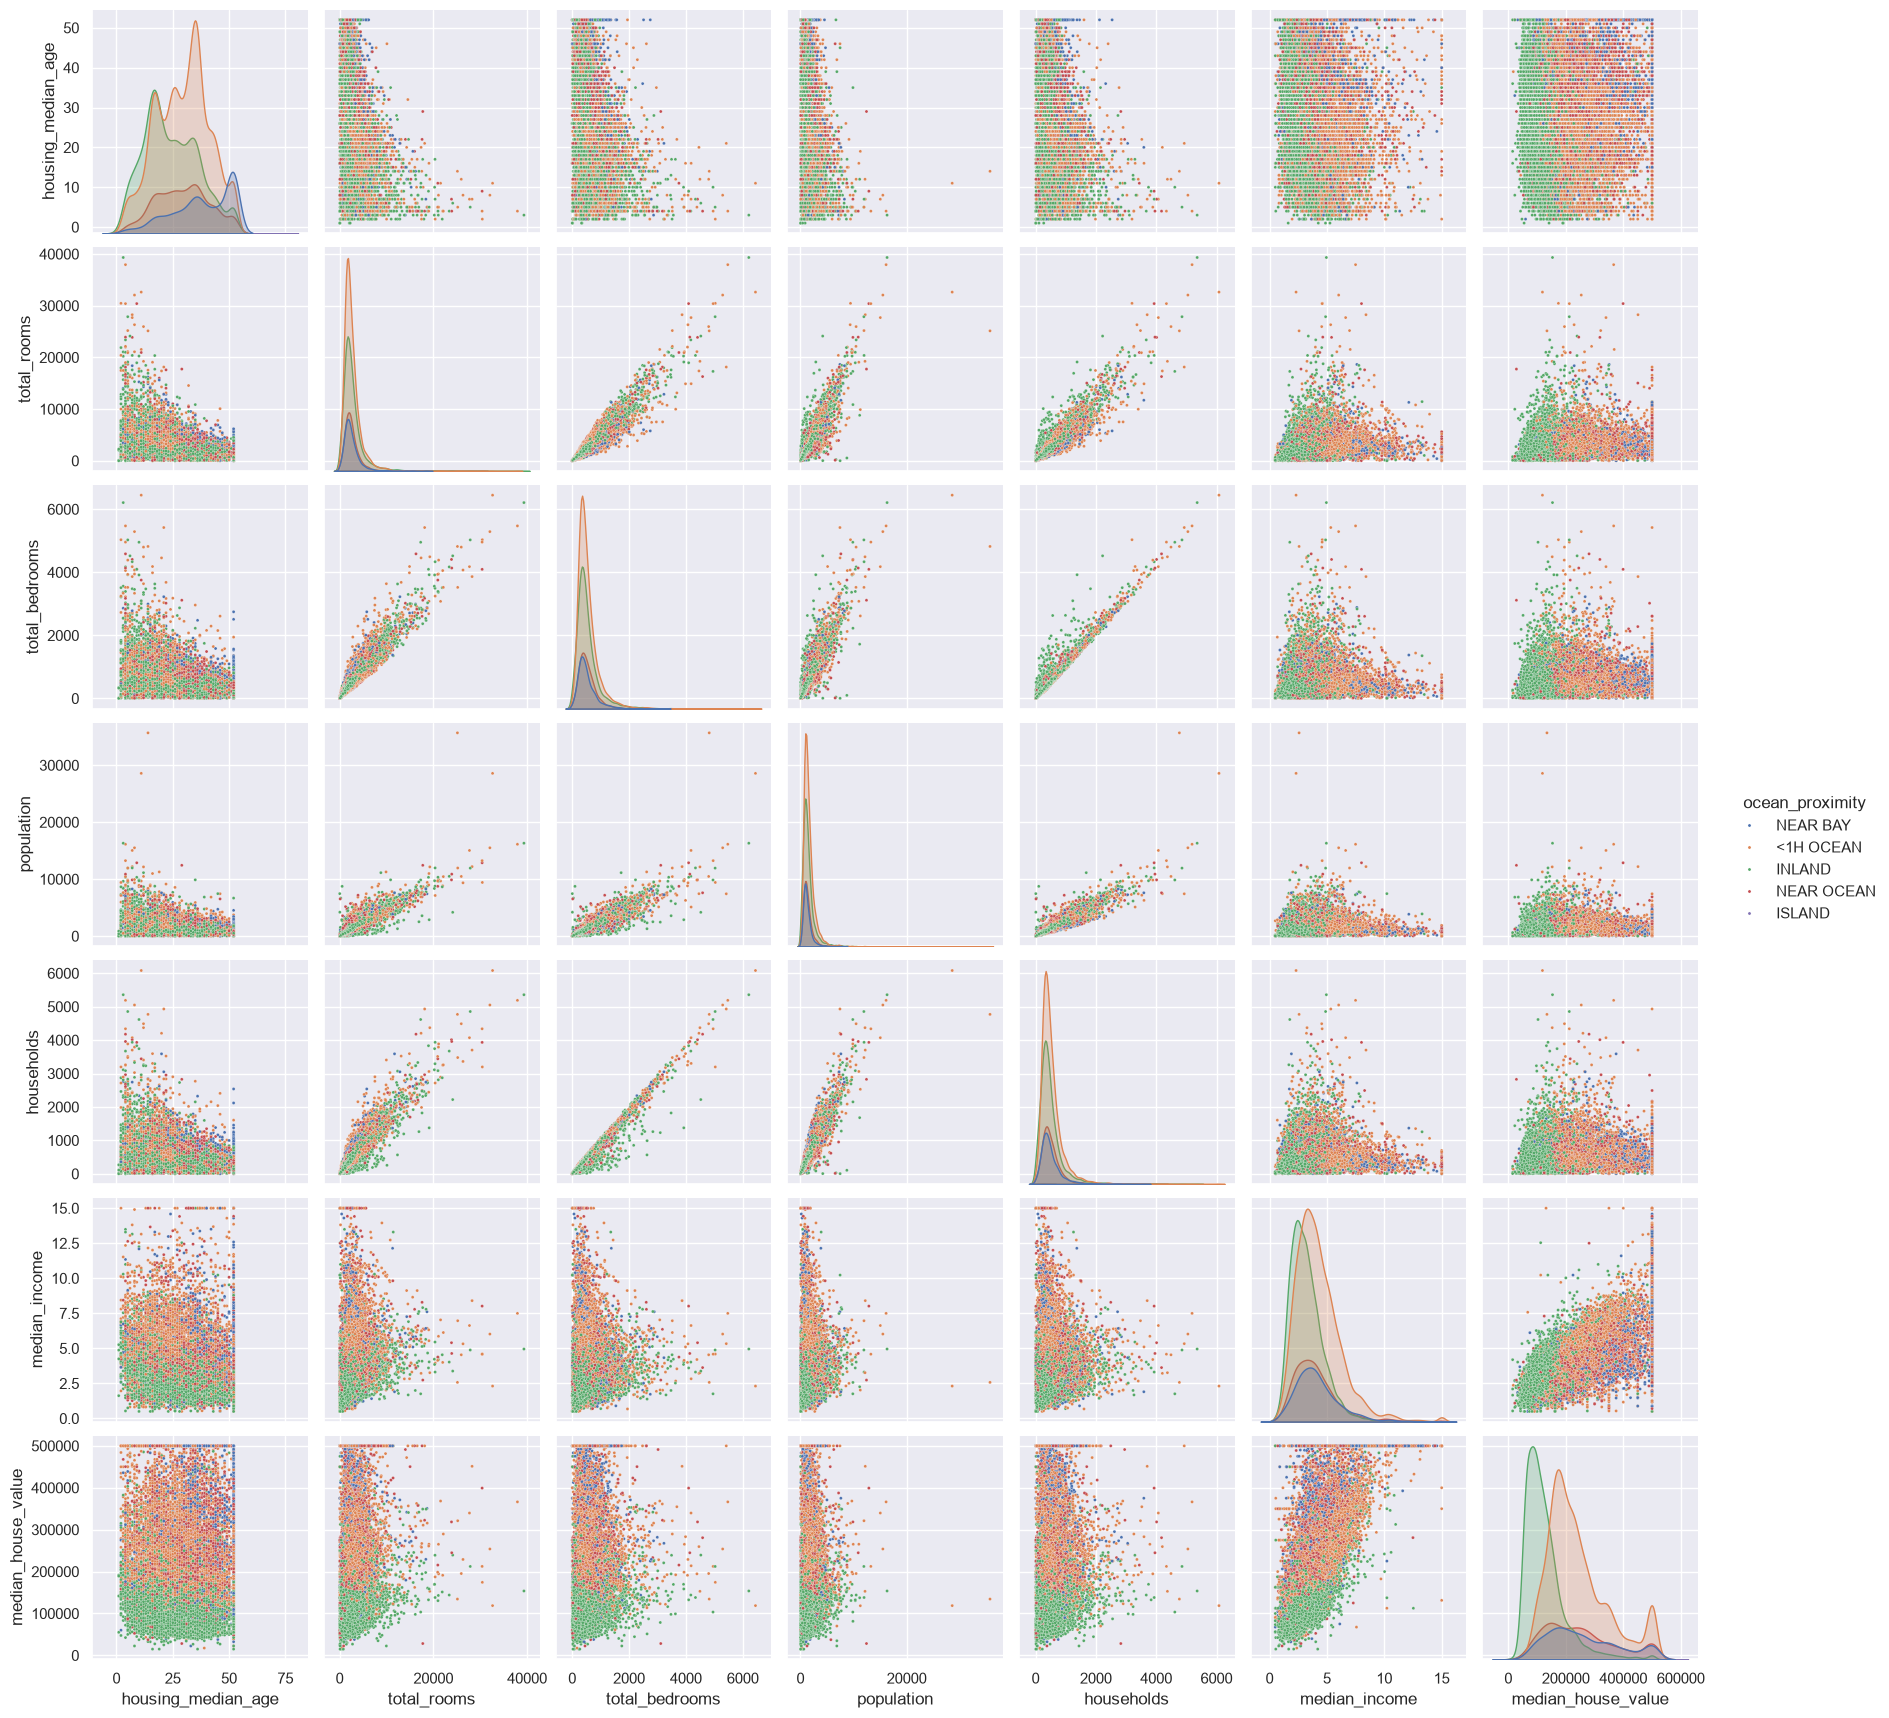

In [7]:
sns.pairplot(df.drop(columns=['longitude', 'latitude']), hue='ocean_proximity', plot_kws={'s': 5})
plt.show()

c) histogramy i wykresy pudelkowe

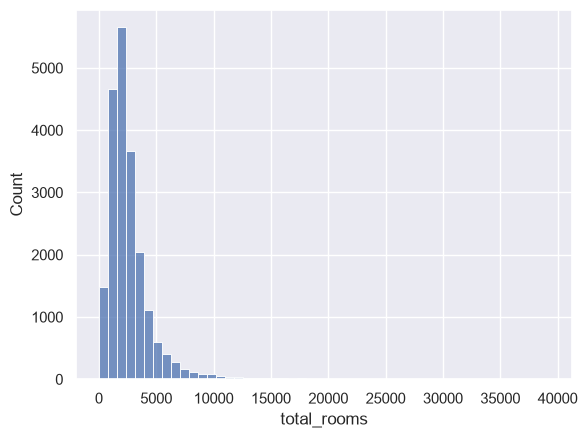

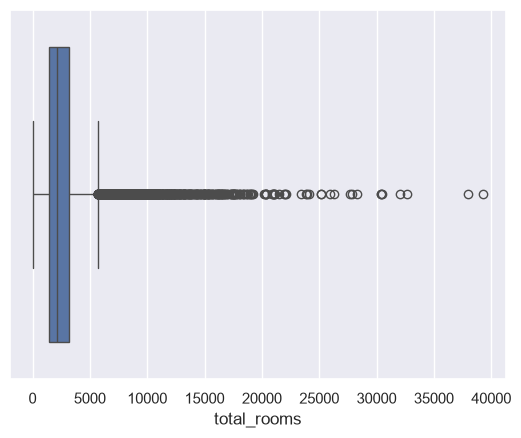

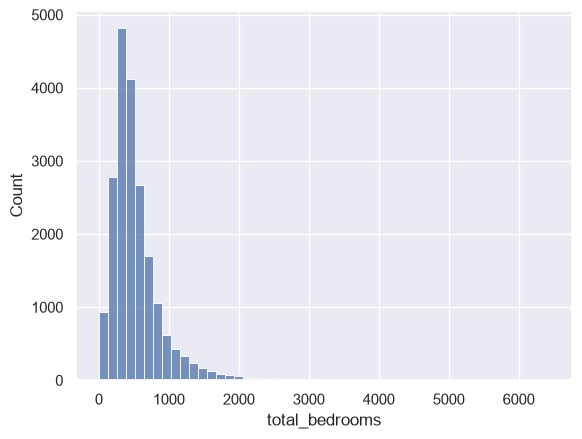

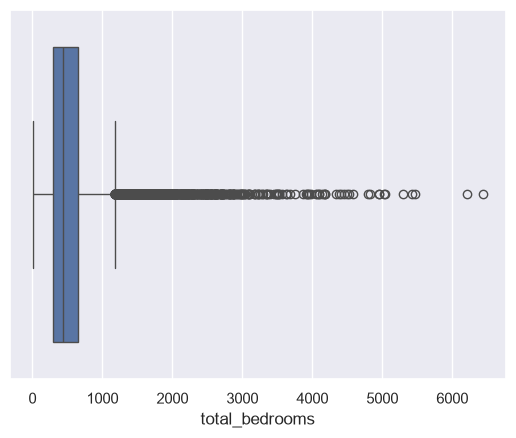

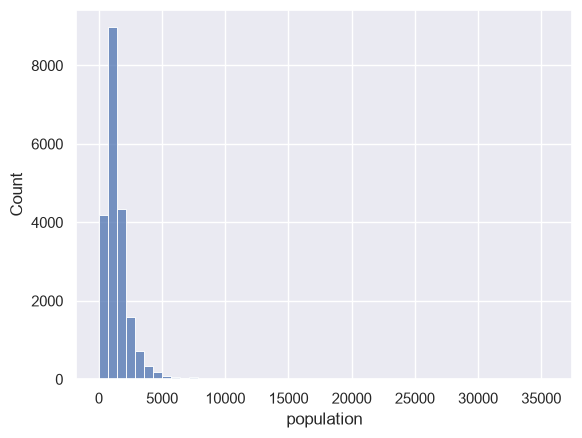

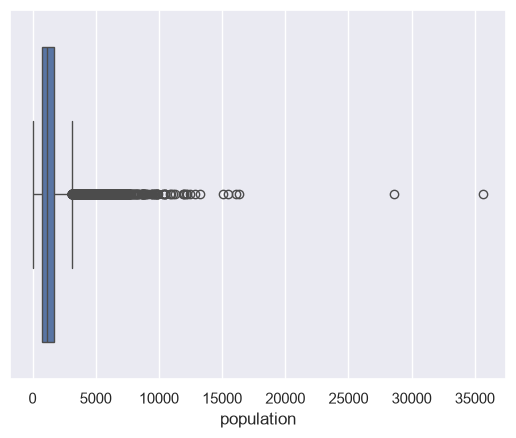

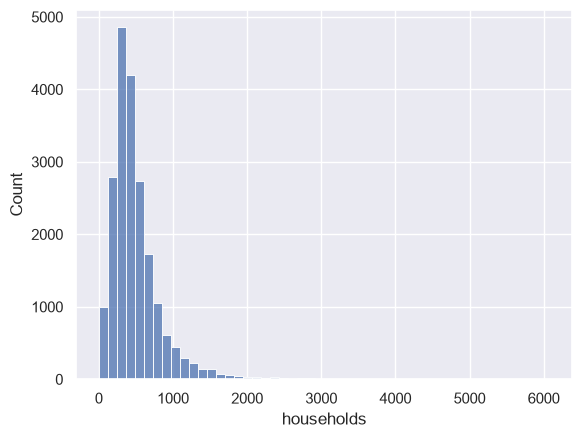

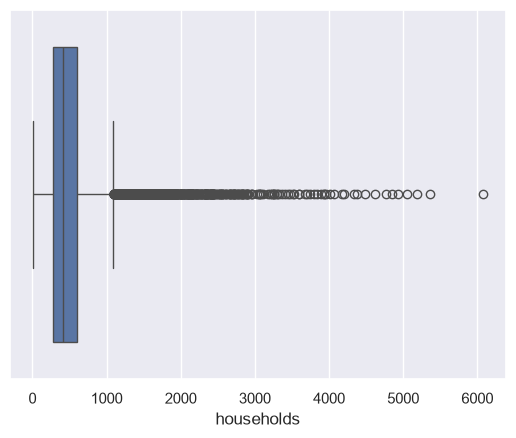

In [8]:
for kolumna in ['total_rooms', 'total_bedrooms', 'population', 'households']:
    sns.histplot(df, x=kolumna, bins=50)
    plt.show()
    sns.boxplot(df, x=kolumna)
    plt.show()

Wszystkie cztery zmienne maja silnie prawostronnie skosne rozklady i bardzo duzo wartosci odstajacych (dlugi 'ogon' w prawo na wykresach pudelkowych) - pojedyncze bloki maja kilkanascie razy wiecej pokoi czy mieszkancow niz typowe.

d) macierz korelacji

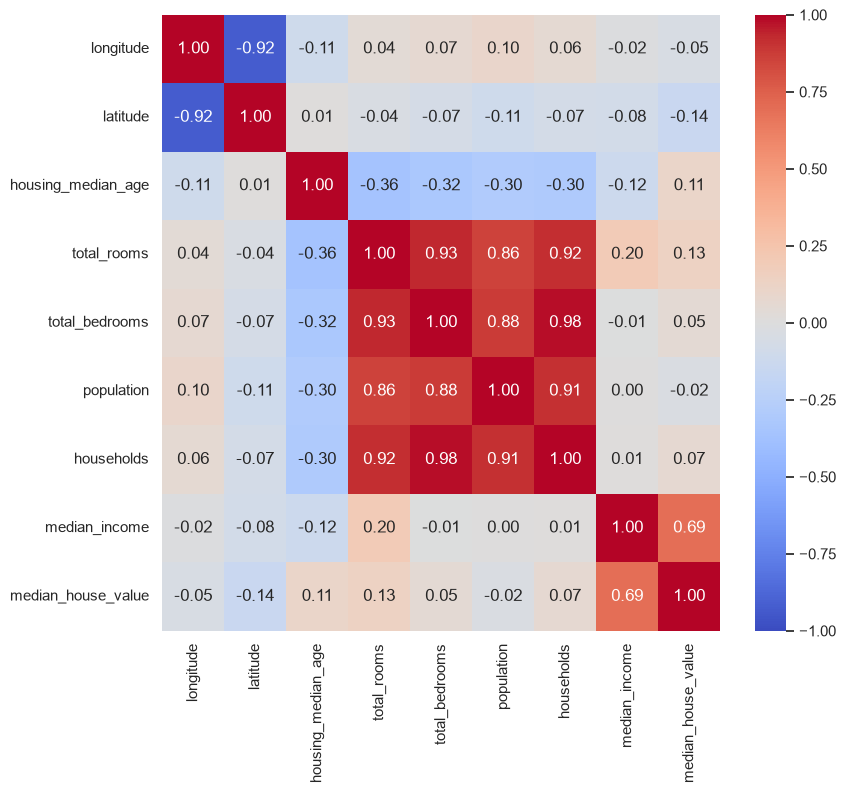

In [9]:
plt.figure(figsize=(9, 8))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1)
plt.show()

# Zadanie 3: Uzupelnianie brakow w danych

a) zmienne najsilniej skorelowane z total_bedrooms

In [10]:
df.select_dtypes('number').corr()['total_bedrooms'].sort_values(ascending=False)

total_bedrooms        1.000000
households            0.979728
total_rooms           0.930380
population            0.877747
longitude             0.069608
median_house_value    0.049686
median_income        -0.007723
latitude             -0.066983
housing_median_age   -0.320451
Name: total_bedrooms, dtype: float64

Najsilniej skorelowane: households (0.98), total_rooms (0.93) i population (0.88) - widac to tez na wykresie par jako prawie liniowe zaleznosci.

b) wektor rows_NA

In [11]:
rows_NA = df['total_bedrooms'].isna()
rows_NA.sum()

np.int64(207)

c) ramka X_OK

In [12]:
kolumny = ['households', 'total_rooms', 'population']
X_OK = df.loc[~rows_NA, kolumny]
X_OK.shape

(20433, 3)

d) seria y_OK

In [13]:
y_OK = df.loc[~rows_NA, 'total_bedrooms']
y_OK.shape

(20433,)

e) model regresji liniowej

In [14]:
from sklearn.linear_model import LinearRegression

lr_NA = LinearRegression()
lr_NA.fit(X_OK, y_OK)
print('wspolczynniki =', lr_NA.coef_)
print('b =', lr_NA.intercept_)
print('R2 =', lr_NA.score(X_OK, y_OK))

wspolczynniki = [ 0.96043235  0.03986646 -0.03345354]
b = 0.7599224681696342
R2 = 0.9670674510465973


f) ramka X_NA

In [15]:
X_NA = df.loc[rows_NA, kolumny]
X_NA.shape

(207, 3)

g) predykcja i uzupelnienie brakow

In [16]:
df.loc[rows_NA, 'total_bedrooms'] = lr_NA.predict(X_NA)
df.loc[rows_NA, ['total_bedrooms'] + kolumny].head()

,total_bedrooms,households,total_rooms,population
290,241.137932,218.0,1256.0,570.0
341,264.571438,259.0,992.0,732.0
538,1303.712347,1273.0,5154.0,3741.0
563,163.657903,146.0,891.0,384.0
696,172.183391,161.0,746.0,387.0


h) weryfikacja

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20640 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


# Zadanie 4: Podzial zbioru, wartosci odstajace, kodowanie, generacja cech

a) podzial na X i y

In [18]:
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']
X.shape, y.shape

((20640, 9), (20640,))

b) przyciecie wartosci odstajacych regula 3 sigma

In [19]:
for kolumna in ['total_rooms', 'total_bedrooms', 'population', 'households']:
    sr = X[kolumna].mean()
    sd = X[kolumna].std()
    print(kolumna, '- odstajace:', ((X[kolumna] < sr - 3*sd) | (X[kolumna] > sr + 3*sd)).sum())
    X[kolumna] = X[kolumna].clip(sr - 3*sd, sr + 3*sd)

X[['total_rooms', 'total_bedrooms', 'population', 'households']].describe()

total_rooms - odstajace: 373
total_bedrooms - odstajace: 371
population - odstajace: 342
households - odstajace: 363


,total_rooms,total_bedrooms,population,households
count,20640.000000,20640.000000,20640.000000,20640.000000
mean,2559.915121,524.509400,1391.108439,487.722965
std,1742.921832,349.625016,922.310900,319.058529
min,2.000000,1.000000,3.000000,1.000000
25%,1447.750000,295.130310,787.000000,280.000000
50%,2127.000000,435.000000,1166.000000,409.000000
75%,3148.000000,647.000000,1725.000000,605.000000
max,9180.608836,1801.501684,4822.863109,1646.528939


c) kodowanie porzadkowe ocean_proximity (ISLAND, NEAR BAY, NEAR OCEAN = 0, <1H OCEAN = 1, INLAND = 2)

In [20]:
X_onehot_baza = X.copy()  # kopia przed kodowaniem - do zadania 7b

X['ocean_proximity'] = X['ocean_proximity'].map({'ISLAND': 0, 'NEAR BAY': 0, 'NEAR OCEAN': 0,
                                                 '<1H OCEAN': 1, 'INLAND': 2})
X['ocean_proximity'].value_counts()

ocean_proximity
1    9136
2    6551
0    4953
Name: count, dtype: int64

d) generacja cech wielomianowych X_2 i X_3

In [21]:
from sklearn.preprocessing import PolynomialFeatures

X_2 = PolynomialFeatures(degree=2, include_bias=False).set_output(transform='pandas').fit_transform(X)
X_3 = PolynomialFeatures(degree=3, include_bias=False).set_output(transform='pandas').fit_transform(X)
print(X.shape, X_2.shape, X_3.shape)
X_2.head()

(20640, 9) (20640, 54) (20640, 219)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,longitude^2,...,population^2,population households,population median_income,population ocean_proximity,households^2,households median_income,households ocean_proximity,median_income^2,median_income ocean_proximity,ocean_proximity^2
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0.0,14940.1729,...,103684.0,40572.0,2680.7144,0.0,15876.0,1048.9752,0.0,69.308955,0.0,0.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0.0,14937.7284,...,5764801.0,2732338.0,19931.6614,0.0,1295044.0,9446.9932,0.0,68.913242,0.0,0.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0.0,14942.6176,...,246016.0,87792.0,3599.6704,0.0,31329.0,1284.5598,0.0,52.669855,0.0,0.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0.0,14945.0625,...,311364.0,122202.0,3148.8498,0.0,47961.0,1235.8389,0.0,31.844578,0.0,0.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0.0,14945.0625,...,319225.0,146335.0,2173.1030,0.0,67081.0,996.1658,0.0,14.793254,0.0,0.0


# Zadanie 5: Zbior treningowy i testowy, uczenie modeli

a) podzial 80:20, random_state=42

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_2_train, X_2_test, _, _ = train_test_split(X_2, y, test_size=0.2, random_state=42)
X_3_train, X_3_test, _, _ = train_test_split(X_3, y, test_size=0.2, random_state=42)
print(X_train.shape, X_2_train.shape, X_3_train.shape, X_test.shape)

(16512, 9) (16512, 54) (16512, 219) (4128, 9)


b) uczenie modeli

In [23]:
zbiory = {
    'liniowa': (X_train, X_test),
    'wielomianowa 2 st.': (X_2_train, X_2_test),
    'wielomianowa 3 st.': (X_3_train, X_3_test),
}

modele = {}
for nazwa, (Xtr, Xte) in zbiory.items():
    modele[nazwa] = LinearRegression().fit(Xtr, y_train)

c) predykcje na zbiorze treningowym i testowym

In [24]:
y_train_preds = {}
y_test_preds = {}
for nazwa, (Xtr, Xte) in zbiory.items():
    y_train_preds[nazwa] = modele[nazwa].predict(Xtr)
    y_test_preds[nazwa] = modele[nazwa].predict(Xte)

list(y_train_preds.keys())

['liniowa', 'wielomianowa 2 st.', 'wielomianowa 3 st.']

# Zadanie 6: Ocena jakosci regresji

a) metryki MAE, RMSE i R2

In [25]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def metryki(y_train_preds, y_test_preds):
    wyniki = {}
    for nazwa in y_train_preds:
        wyniki[nazwa] = {
            'MAE train': mean_absolute_error(y_train, y_train_preds[nazwa]),
            'MAE test': mean_absolute_error(y_test, y_test_preds[nazwa]),
            'RMSE train': root_mean_squared_error(y_train, y_train_preds[nazwa]),
            'RMSE test': root_mean_squared_error(y_test, y_test_preds[nazwa]),
            'R2 train': r2_score(y_train, y_train_preds[nazwa]),
            'R2 test': r2_score(y_test, y_test_preds[nazwa]),
        }
    return wyniki

wyniki = metryki(y_train_preds, y_test_preds)
for nazwa, m in wyniki.items():
    print(nazwa, {k: round(v, 3) for k, v in m.items()})

liniowa {'MAE train': 49511.841, 'MAE test': 49839.558, 'RMSE train': 67828.989, 'RMSE test': 68501.532, 'R2 train': 0.656, 'R2 test': 0.642}
wielomianowa 2 st. {'MAE train': 43202.545, 'MAE test': 43744.641, 'RMSE train': 60854.016, 'RMSE test': 62043.562, 'R2 train': 0.723, 'R2 test': 0.706}
wielomianowa 3 st. {'MAE train': 40171.984, 'MAE test': 41124.443, 'RMSE train': 56890.135, 'RMSE test': 58535.953, 'R2 train': 0.758, 'R2 test': 0.739}


b) ramka danych z metrykami

In [26]:
tabela = pd.DataFrame(wyniki).T
tabela.round(3)

,MAE train,MAE test,RMSE train,RMSE test,R2 train,R2 test
liniowa,49511.841,49839.558,67828.989,68501.532,0.656,0.642
wielomianowa 2 st.,43202.545,43744.641,60854.016,62043.562,0.723,0.706
wielomianowa 3 st.,40171.984,41124.443,56890.135,58535.953,0.758,0.739


# Zadanie 7: Dostrajanie modelu

a) stopien wielomianu 4 i 5 (kodowanie porzadkowe)

In [27]:
for stopien in [4, 5]:
    Xs = PolynomialFeatures(degree=stopien, include_bias=False).set_output(transform='pandas').fit_transform(X)
    Xs_train, Xs_test, _, _ = train_test_split(Xs, y, test_size=0.2, random_state=42)
    model = LinearRegression().fit(Xs_train, y_train)
    nazwa = f'wielomianowa {stopien} st.'
    y_train_preds[nazwa] = model.predict(Xs_train)
    y_test_preds[nazwa] = model.predict(Xs_test)
    print(nazwa, '- liczba cech:', Xs.shape[1])

pd.DataFrame(metryki(y_train_preds, y_test_preds)).T.round(3)

wielomianowa 4 st. - liczba cech: 714
wielomianowa 5 st. - liczba cech: 2001


,MAE train,MAE test,RMSE train,RMSE test,R2 train,R2 test
liniowa,49511.841,49839.558,67828.989,68501.532,0.656,0.642
wielomianowa 2 st.,43202.545,43744.641,60854.016,62043.562,0.723,0.706
wielomianowa 3 st.,40171.984,41124.443,56890.135,58535.953,0.758,0.739
wielomianowa 4 st.,39556.838,41458.519,55630.950,60984.193,0.768,0.716
wielomianowa 5 st.,40445.596,44099.502,56417.940,69400.303,0.762,0.632


b) kodowanie one-hot zamiast porzadkowego

In [28]:
X_oh = pd.get_dummies(X_onehot_baza, columns=['ocean_proximity'], dtype=int)
X_oh.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0,0,0,1,0


In [29]:
y_train_preds_oh = {}
y_test_preds_oh = {}
for stopien in [1, 2, 3, 4, 5]:
    Xs = X_oh if stopien == 1 else \
        PolynomialFeatures(degree=stopien, include_bias=False).set_output(transform='pandas').fit_transform(X_oh)
    Xs_train, Xs_test, _, _ = train_test_split(Xs, y, test_size=0.2, random_state=42)
    model = LinearRegression().fit(Xs_train, y_train)
    nazwa = 'liniowa (one-hot)' if stopien == 1 else f'wielomianowa {stopien} st. (one-hot)'
    y_train_preds_oh[nazwa] = model.predict(Xs_train)
    y_test_preds_oh[nazwa] = model.predict(Xs_test)
    print(nazwa, '- liczba cech:', Xs.shape[1])

liniowa (one-hot) - liczba cech: 13
wielomianowa 2 st. (one-hot) - liczba cech: 104
wielomianowa 3 st. (one-hot) - liczba cech: 559
wielomianowa 4 st. (one-hot) - liczba cech: 2379
wielomianowa 5 st. (one-hot) - liczba cech: 8567


c) porownanie wszystkich modeli

In [30]:
tabela_all = pd.concat([pd.DataFrame(metryki(y_train_preds, y_test_preds)).T,
                        pd.DataFrame(metryki(y_train_preds_oh, y_test_preds_oh)).T])
tabela_all.round(3)

,MAE train,MAE test,RMSE train,RMSE test,R2 train,R2 test
liniowa,49511.841,49839.558,67828.989,68501.532,0.656,0.642
wielomianowa 2 st.,43202.545,43744.641,60854.016,62043.562,0.723,0.706
wielomianowa 3 st.,40171.984,41124.443,56890.135,58535.953,0.758,0.739
wielomianowa 4 st.,39556.838,41458.519,55630.950,60984.193,0.768,0.716
wielomianowa 5 st.,40445.596,44099.502,56417.940,69400.303,0.762,0.632
liniowa (one-hot),48969.788,49532.594,67280.261,68160.747,0.661,0.645
wielomianowa 2 st. (one-hot),42500.275,43102.270,59832.090,61300.748,0.732,0.713
wielomianowa 3 st. (one-hot),38982.839,39864.373,55510.709,57435.317,0.769,0.748
wielomianowa 4 st. (one-hot),38695.508,41000.600,54481.212,61727.062,0.778,0.709
wielomianowa 5 st. (one-hot),39417.431,44326.400,55342.468,81515.052,0.771,0.493


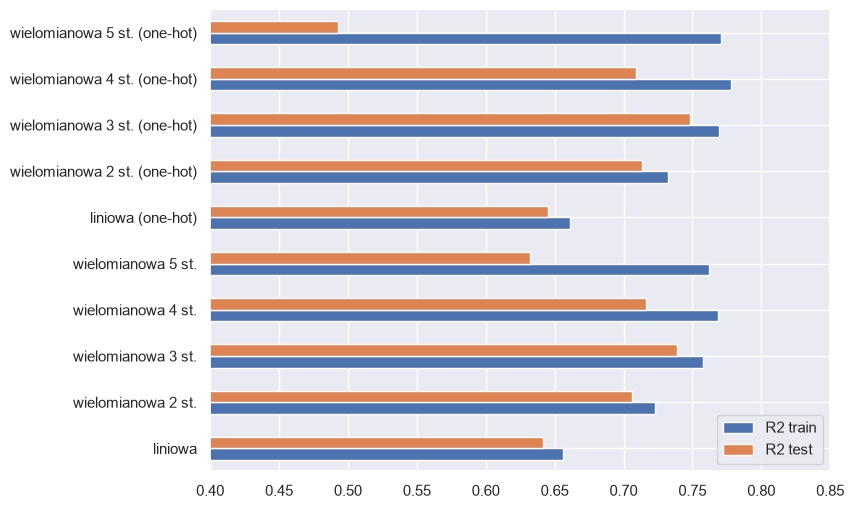

In [31]:
tabela_all[['R2 train', 'R2 test']].plot(kind='barh', figsize=(8, 6))
plt.xlim(0.4, 0.85)
plt.show()

Wnioski

Najlepszy jest model wielomianowy 3 stopnia - z kodowaniem one-hot R2 na testowych 0.748 (porzadkowe 0.739), RMSE ok. 57-58 tys. Stopnie 2 i 3 poprawiaja wynik wzgledem prostej regresji liniowej (R2 0.64), a roznica train/test jest mala.

Stopien 4 i 5 nie ma sensu: na treningowych R2 jeszcze troche rosnie, ale na testowych spada (stopien 5 z one-hot: 0.77 train vs 0.49 test) - modele sa przetrenowane, bo maja tysiace cech (do 8567).

One-hot daje troche lepsze wyniki niz kodowanie porzadkowe dla stopni 1-3, ale przy wysokich stopniach generuje duzo wiecej cech i szybciej sie przetrenowuje.